# 04 · Pronóstico mensual por distrito con backtesting de origen móvil

- Series mensuales completas por distrito hasta el **último mes completo** (el mes en curso se excluye).
- Variables sin fuga: rezagos 1, 2, 3 y 12 y medias móviles del pasado.
- **8 cortes trimestrales**: en cada uno se reentrena con lo anterior y se pronostica un mes adelante durante 3 meses.
- **Intervalos de predicción al 90 %** calibrados con los errores de los 12 meses previos al corte, que el modelo no vio.

In [1]:
import json
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from delitos_chicago.config import FIGURAS, PROCESADOS, REPORTES
import delitos_chicago.pipeline  # los módulos fijan el backend Agg al importarse; después se activa el inline
%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

In [2]:
from delitos_chicago.pipeline import cargar_datos
from delitos_chicago.pronostico import ultimo_mes_completo
df, renombres, conteos = cargar_datos(PROCESADOS / "delitos_parquet")
mes_completo = ultimo_mes_completo(df["fecha"].max())
anio_completo = mes_completo.year if mes_completo.month == 12 else mes_completo.year - 1
completos = df[df["anio"] <= anio_completo]
print(f"{len(df):,} registros · último dato {df['fecha'].max():%Y-%m-%d} · último mes completo {mes_completo:%Y-%m} · años completos 2001–{anio_completo}")

8,665,676 registros · último dato 2026-10-16 · último mes completo 2026-09 · años completos 2001–2025


In [3]:
from delitos_chicago import pronostico
serie = pronostico.preparar_series_mensuales_distrito(df, hasta=mes_completo)
caracteristicas = pronostico.construir_caracteristicas_tiempo(serie)
print(f"{serie['distrito'].nunique()} distritos · {serie['fecha'].min():%Y-%m} a {serie['fecha'].max():%Y-%m}")
caracteristicas.tail(3)

22 distritos · 2001-01 a 2026-09


,fecha,distrito,delitos,mes,tendencia,lag_1,lag_2,lag_3,lag_12,media_movil_3,media_movil_6,linea_base_estacional,linea_base_promedio
6531,2026-07-01,25,1100,7,306,1020.0,1112.0,987.0,1069.0,1039.666667,962.666667,1069.0,1039.666667
6532,2026-08-01,25,1043,8,307,1100.0,1020.0,1112.0,1002.0,1077.333333,1008.500000,1002.0,1077.333333
6533,2026-09-01,25,1014,9,308,1043.0,1100.0,1020.0,977.0,1054.333333,1047.500000,977.0,1054.333333


## 1. Comprobación de que no hay fuga: alterar el futuro no cambia las variables del pasado

In [4]:
corte = mes_completo - pd.DateOffset(months=12)
alterada = serie.copy()
alterada.loc[alterada["fecha"] >= corte, "delitos"] *= 10
a = pronostico.construir_caracteristicas_tiempo(serie).set_index(["distrito", "fecha"])
b = pronostico.construir_caracteristicas_tiempo(alterada).set_index(["distrito", "fecha"])
columnas = [c for c in a.columns if c != "delitos"]
hasta = a.index.get_level_values("fecha") <= corte
print("Variables idénticas hasta el corte:", a.loc[hasta, columnas].equals(b.loc[hasta, columnas]))

Variables idénticas hasta el corte: True


## 2. Backtesting de origen móvil

In [5]:
origenes = pronostico.origenes_trimestrales(mes_completo)
bt = pronostico.backtesting_origen_movil(caracteristicas, origenes)
print("Ganador:", bt["ganador"], "· mejora vs. base estacional:", bt["mejora_ganador_vs_estacional_pct"], "%")
pd.DataFrame(bt["metricas"]).T

Ganador: Modelo_Ridge · mejora vs. base estacional: 32.2 %


,MAE,RMSE,WAPE_pct,Sesgo_pct,WAPE_medio_por_corte,WAPE_desv_por_corte,cortes_ganados,cobertura_pct,ancho_relativo_mediano_pct
Linea_Base_Estacional_t12,82.34,103.43,9.16,6.61,9.20,1.34,0.0,85.4,28.7
Linea_Base_Promedio_Movil3,80.38,99.52,8.94,1.19,9.02,2.02,0.0,85.4,33.4
Modelo_Ridge,55.82,71.82,6.21,1.96,6.28,2.02,5.0,86.4,24.0
Modelo_Random_Forest,56.47,71.21,6.28,2.11,6.32,1.34,3.0,86.2,23.5


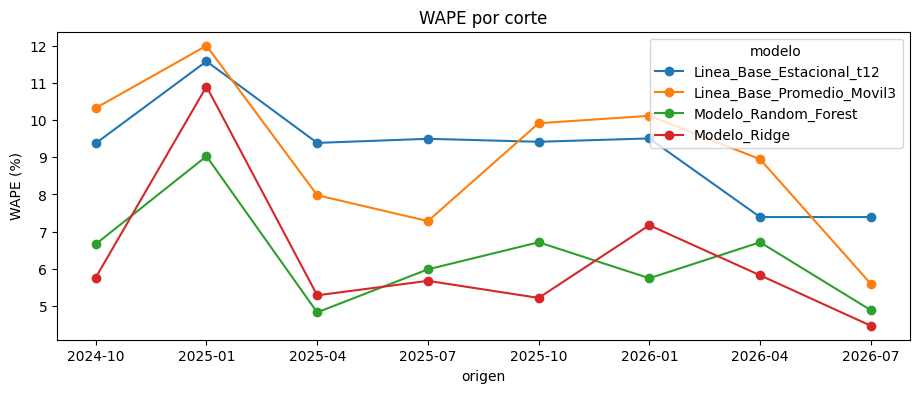

In [6]:
tabla = bt["por_origen"].pivot(index="origen", columns="modelo", values="WAPE_pct")
ax = tabla.plot(marker="o", figsize=(11, 4))
ax.set_ylabel("WAPE (%)")
ax.set_title("WAPE por corte")
plt.show()

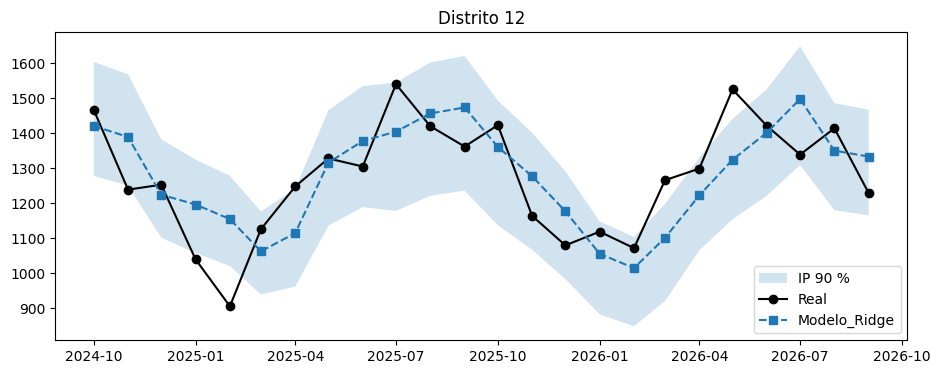

Cobertura del intervalo del 90 % en todos los distritos: 86.4 %


In [7]:
g = bt["ganador"]
r = bt["resultados"]
top = r.groupby("distrito")["delitos"].sum().idxmax()
d = r[r["distrito"] == top].set_index("fecha")
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(d.index, d[f"inf_{g}"], d[f"sup_{g}"], alpha=0.2, label="IP 90 %")
ax.plot(d.index, d["delitos"], "o-", color="black", label="Real")
ax.plot(d.index, d[f"pred_{g}"], "s--", label=g)
ax.set_title(f"Distrito {top}")
ax.legend()
plt.show()
print(f"Cobertura del intervalo del 90 % en todos los distritos: {bt['metricas'][g]['cobertura_pct']} %")

El modelo lineal (Ridge) y el Random Forest quedan muy cerca y ambos reducen el error frente a las líneas base. La cobertura del intervalo queda algo por debajo del 90 % nominal: conviene leerlo como un rango algo optimista.